<a href="https://colab.research.google.com/github/dapenuela/ML-NO-SUPERVISADO/blob/main/ML_No_Supervisado_Iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clustering y reducción de dimensionalidad con Iris
**Diego Armando Peñuela Cárdenas** · Especialización en Inteligencia Artificial

Ejercicio académico introductorio. Abra este notebook en Google Colab y elija **Entorno de ejecución > Ejecutar todas**. Las salidas incluidas se obtuvieron en Python en el entorno de preparación; vuelva a ejecutarlo en Colab para comprobarlas allí. No se requiere descargar un archivo de datos.

## Objetivo
Explorar grupos de flores mediante K-means y clustering jerárquico, y representar las cuatro variables mediante PCA y SVD. Las etiquetas de especie no se utilizan para ajustar los modelos ni para elegir k.


In [ ]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
Path('figuras').mkdir(exist_ok=True)
print('Python:', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__, '| NumPy:', np.__version__)
print('pandas:', pd.__version__, '| SciPy:', scipy.__version__, '| Matplotlib:', matplotlib.__version__)


Python: 3.12.14
scikit-learn: 1.8.0 | NumPy: 2.3.5
pandas: 2.2.3 | SciPy: 1.17.0 | Matplotlib: 3.10.8


## 1. Datos y preparación
Iris contiene 150 flores y cuatro medidas en centímetros: largo y ancho del sépalo y del pétalo. Se verifican faltantes y se estandariza cada variable para que las distancias no estén dominadas por su escala. Este análisis es exploratorio sobre el conjunto completo; no estima generalización a datos nuevos.

In [ ]:
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
print('Dimensiones:', X.shape)
print('Faltantes:', int(X.isna().sum().sum()))
print(X.describe().round(3).to_string())
scaler = StandardScaler()
Z = scaler.fit_transform(X)


Dimensiones: (150, 4)
Faltantes: 0
       sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
count            150.000           150.000            150.000           150.000
mean               5.843             3.057              3.758             1.199
std                0.828             0.436              1.765             0.762
min                4.300             2.000              1.000             0.100
25%                5.100             2.800              1.600             0.300
50%                5.800             3.000              4.350             1.300
75%                6.400             3.300              5.100             1.800
max                7.900             4.400              6.900             2.500


## 2. Selección exploratoria de k
Se prueban de 2 a 6 grupos. La silueta compara cohesión y separación: valores altos son preferibles, pero no identifican necesariamente especies. Se usan 20 inicializaciones y semilla 42 para K-means.

 k  inercia  silueta
 2 222.3617   0.5818
 3 139.8205   0.4599
 4 114.0923   0.3845
 5  90.8076   0.3455
 6  80.0222   0.3220
k elegido por mayor silueta: 2


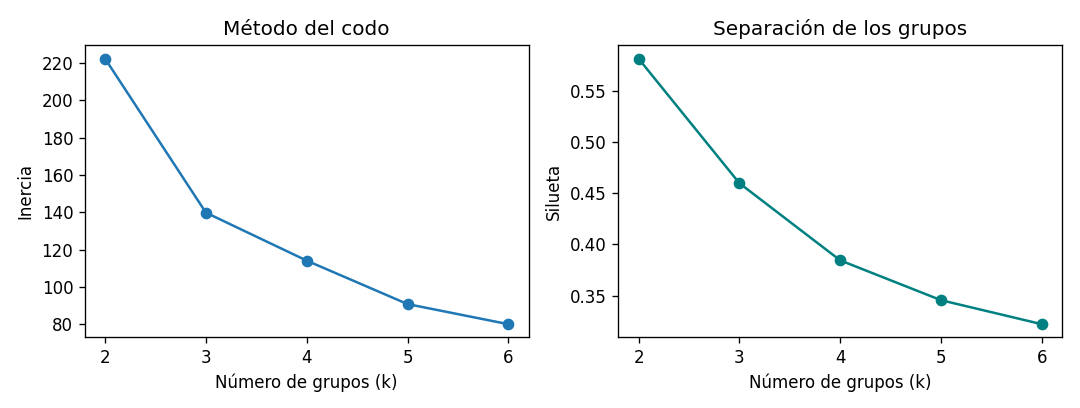

In [ ]:
filas = []
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, n_init=20, random_state=42)
    grupos = modelo.fit_predict(Z)
    filas.append({'k': k, 'inercia': modelo.inertia_, 'silueta': silhouette_score(Z, grupos)})
comparacion = pd.DataFrame(filas)
print(comparacion.round(4).to_string(index=False))
k_elegido = int(comparacion.loc[comparacion['silueta'].idxmax(), 'k'])
print('k elegido por mayor silueta:', k_elegido)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(comparacion.k, comparacion.inercia, 'o-')
ax[0].set(xlabel='Número de grupos (k)', ylabel='Inercia', title='Método del codo')
ax[1].plot(comparacion.k, comparacion.silueta, 'o-', color='teal')
ax[1].set(xlabel='Número de grupos (k)', ylabel='Silueta', title='Separación de los grupos')
fig.tight_layout(); fig.savefig('figuras/seleccion_k.png', dpi=180); plt.show()


## 3. K-means y clustering jerárquico
Se comparan ambos métodos con el mismo k. Ward une progresivamente los grupos que menos aumentan la dispersión interna, usando distancias euclidianas. El dendrograma muestra esta secuencia; no se interpreta como una clasificación biológica. También se informa k=3 como análisis de sensibilidad, sin utilizar etiquetas.

         metodo  k  silueta      tamanos
        K-means  2   0.5818    [50, 100]
Jerárquico Ward  2   0.5770    [49, 101]
        K-means  3   0.4599 [47, 50, 53]
Jerárquico Ward  3   0.4467 [30, 49, 71]

Centros K-means en centímetros:
 sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
             6.262             2.872              4.906             1.676
             5.006             3.428              1.462             0.246


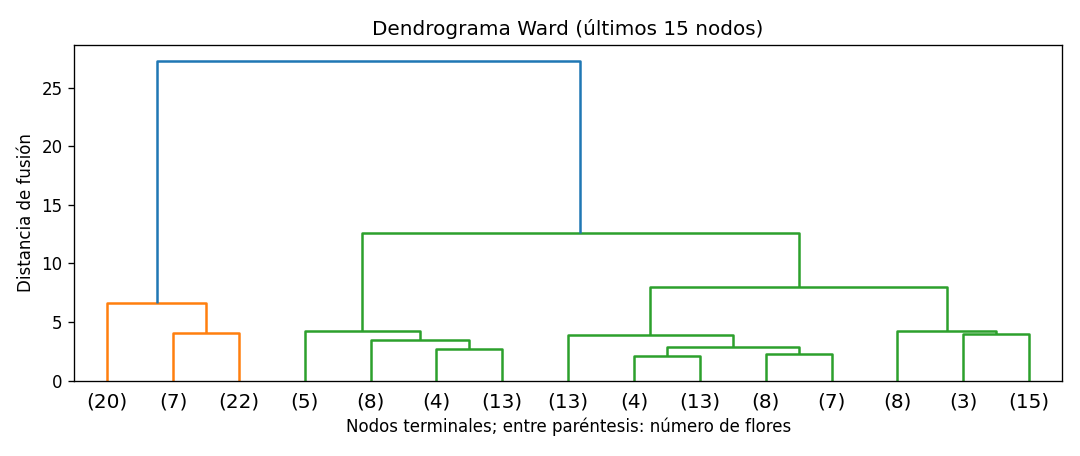

In [ ]:
km = KMeans(n_clusters=k_elegido, n_init=20, random_state=42)
labels_km = km.fit_predict(Z)
hc = AgglomerativeClustering(n_clusters=k_elegido, linkage='ward')
labels_hc = hc.fit_predict(Z)
res = []
for k in (k_elegido, 3):
    for nombre, modelo in [('K-means', KMeans(n_clusters=k, n_init=20, random_state=42)),
                           ('Jerárquico Ward', AgglomerativeClustering(n_clusters=k, linkage='ward'))]:
        labels = modelo.fit_predict(Z)
        res.append({'metodo': nombre, 'k': k, 'silueta': silhouette_score(Z, labels),
                    'tamanos': sorted(np.bincount(labels).tolist())})
print(pd.DataFrame(res).round(4).to_string(index=False))
print('\nCentros K-means en centímetros:')
print(pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=X.columns).round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 3.8))
dendrogram(linkage(Z, method='ward'), truncate_mode='lastp', p=15, ax=ax)
ax.set(title='Dendrograma Ward (últimos 15 nodos)', xlabel='Nodos terminales; entre paréntesis: número de flores', ylabel='Distancia de fusión')
fig.tight_layout(); fig.savefig('figuras/dendrograma.png', dpi=180); plt.show()


## 4. PCA y SVD
PCA construye componentes ortogonales que concentran varianza. SVD factoriza una matriz como UΣVᵀ; TruncatedSVD conserva una aproximación de rango reducido y no centra automáticamente los datos. Aquí ambos reciben Z ya centrada por StandardScaler, por lo que se esperan resultados prácticamente equivalentes. No son dos evidencias independientes. Se calcula el error cuadrático medio de reconstrucción sobre Z.

PCA - varianza por componente: [0.729624 0.228508]
PCA - varianza acumulada: 0.958132
SVD - varianza acumulada: 0.958132
MSE de reconstrucción PCA: 0.041868
MSE de reconstrucción SVD: 0.041868


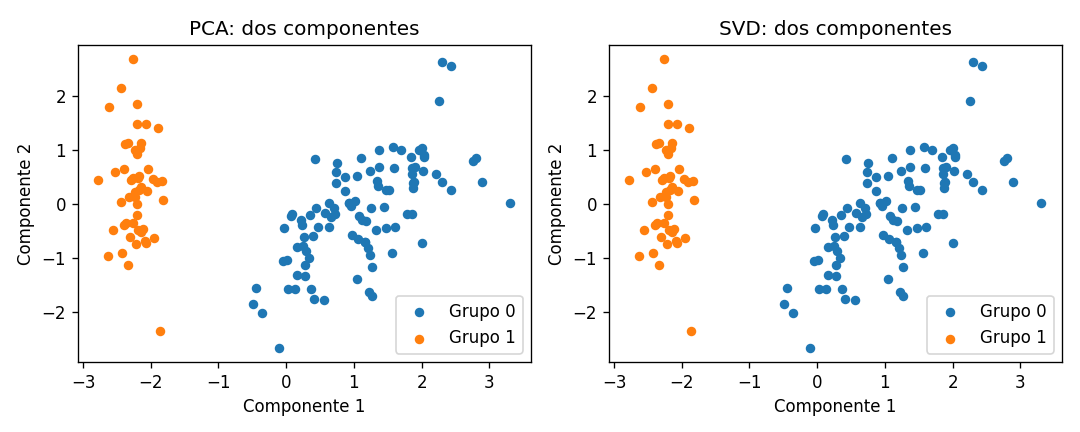

In [ ]:
pca = PCA(n_components=2, svd_solver='full')
P = pca.fit_transform(Z)
svd = TruncatedSVD(n_components=2, n_iter=10, random_state=42)
S = svd.fit_transform(Z)
mse_pca = float(np.mean((Z - pca.inverse_transform(P)) ** 2))
mse_svd = float(np.mean((Z - svd.inverse_transform(S)) ** 2))
print('PCA - varianza por componente:', pca.explained_variance_ratio_.round(6))
print('PCA - varianza acumulada:', round(pca.explained_variance_ratio_.sum(), 6))
print('SVD - varianza acumulada:', round(svd.explained_variance_ratio_.sum(), 6))
print('MSE de reconstrucción PCA:', round(mse_pca, 6))
print('MSE de reconstrucción SVD:', round(mse_svd, 6))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, coords, titulo in zip(ax, (P, S), ('PCA: dos componentes', 'SVD: dos componentes')):
    for g in np.unique(labels_km):
        a.scatter(coords[labels_km==g, 0], coords[labels_km==g, 1], s=22, label=f'Grupo {g}')
    a.set(title=titulo, xlabel='Componente 1', ylabel='Componente 2'); a.legend()
fig.tight_layout(); fig.savefig('figuras/reduccion.png', dpi=180); plt.show()


## 5. Comparación visual de los grupos
Los algoritmos se ajustaron sobre las cuatro variables estandarizadas. PCA solo se usa como plano para visualizar: el solapamiento en dos dimensiones no equivale a identidad en cuatro dimensiones. Los números de grupo son arbitrarios entre métodos.

Resultados y gráficas guardados.


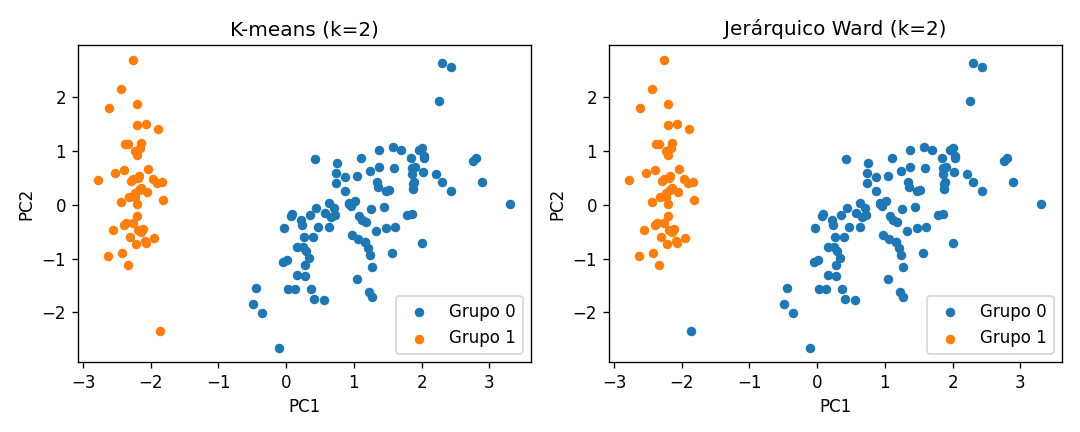

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, labels, titulo in zip(ax, (labels_km, labels_hc), ('K-means', 'Jerárquico Ward')):
    for g in np.unique(labels):
        a.scatter(P[labels==g, 0], P[labels==g, 1], s=22, label=f'Grupo {g}')
    a.set(title=f'{titulo} (k={k_elegido})', xlabel='PC1', ylabel='PC2'); a.legend()
fig.tight_layout(); fig.savefig('figuras/clusters.png', dpi=180); plt.show()
metricas = {'k': k_elegido, 'comparacion_k': filas, 'clustering': res,
            'pca_varianza': pca.explained_variance_ratio_.tolist(),
            'svd_varianza': float(svd.explained_variance_ratio_.sum()),
            'mse_pca': mse_pca, 'mse_svd': mse_svd}
Path('resultados.json').write_text(json.dumps(metricas, indent=2), encoding='utf-8')
print('Resultados y gráficas guardados.')


## 6. Reflexión y límites
El criterio de silueta prefiere dos grupos en esta ejecución; esto no implica que existan únicamente dos especies. Al forzar tres grupos se obtiene otra descripción, con menor separación según esa métrica. PCA y SVD conservan cerca del 96 % de la varianza, pero esa proporción no es exactitud predictiva. En un trabajo posterior probaría otros datos, distancias y métodos, y revisaría la estabilidad al cambiar la semilla.

## Referencias
The scikit-learn developers. (s. f.). *Clustering*. https://scikit-learn.org/stable/modules/clustering.html

The scikit-learn developers. (s. f.). *PCA*. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html

The scikit-learn developers. (s. f.). *TruncatedSVD*. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html

The scikit-learn developers. (s. f.). *load_iris*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
